<a href="https://colab.research.google.com/github/Mutaqie/Latihan-Machine-Learning/blob/main/Pertemuan%203/Latihan_3_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

print("Semua library berhasil di-import")

Semua library berhasil di-import


In [ ]:
#1. Siapkan Data Set

In [2]:
rng = np.random.RandomState(42)

X_arr, y_arr = make_classification(
    n_samples=1000, n_features=8, n_informative=5, n_redundant=1,
    weights=[0.95, 0.05], class_sep=0.8, flip_y=0.01, random_state=42)

kolom = [f"fitur_{i+1}" for i in range(X_arr.shape[1])]
X = pd.DataFrame(X_arr, columns=kolom)
y = pd.Series(y_arr, name="fraud")

# Buat missing values (±8%) pada 3 fitur
for k in ["fitur_2", "fitur_4", "fitur_6"]:
    idx = rng.choice(len(X), size=int(0.08 * len(X)), replace=False)
    X.loc[idx, k] = np.nan

print("Bentuk data X:", X.shape)
X.head()

Bentuk data X: (1000, 8)


,fitur_1,fitur_2,fitur_3,fitur_4,fitur_5,fitur_6,fitur_7,fitur_8
0,-0.356981,-1.336151,-1.960643,-0.776603,1.389764,0.487997,-0.334010,-1.345210
1,1.616122,-0.208466,0.908788,1.206679,-0.503570,0.264431,1.674593,-0.150614
2,-0.729057,0.103553,0.863402,2.571347,-1.244486,3.289827,3.005749,0.449827
3,-1.785427,-1.370651,-0.795596,1.595308,0.498883,3.177289,2.118571,-0.342149
4,0.901592,-0.816916,0.563332,0.944059,-0.566705,-0.234817,0.937984,-0.599821


In [ ]:
#2. Eksplorasi: distribusi kelas dan missing values

In [3]:
print("Jumlah per kelas:")
print(y.value_counts().rename({0: "Normal (0)", 1: "Fraud (1)"}))
print("\nProporsi (%):")
print((y.value_counts(normalize=True) * 100).round(1).rename({0: "Normal (0)", 1: "Fraud (1)"}))

print("\nMissing values per kolom:")
miss = X.isna().sum()
print(miss[miss > 0])
print("Total sel kosong:", int(X.isna().sum().sum()))

Jumlah per kelas:
fraud
Normal (0)    946
Fraud (1)      54
Name: count, dtype: int64

Proporsi (%):
fraud
Normal (0)    94.6
Fraud (1)      5.4
Name: proportion, dtype: float64

Missing values per kolom:
fitur_2    80
fitur_4    80
fitur_6    80
dtype: int64
Total sel kosong: 240


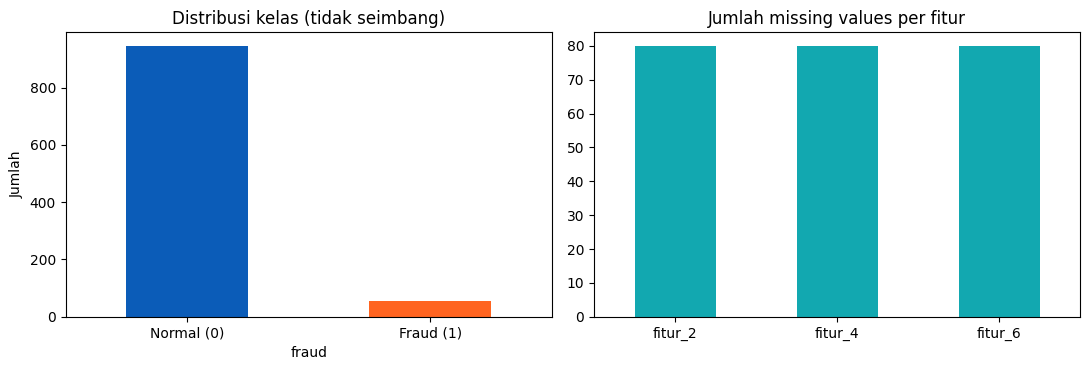

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

y.value_counts().sort_index().plot(kind="bar", ax=ax[0], color=["#0b5cb8", "#ff6420"])
ax[0].set_xticklabels(["Normal (0)", "Fraud (1)"], rotation=0)
ax[0].set_title("Distribusi kelas (tidak seimbang)")
ax[0].set_ylabel("Jumlah")

miss[miss > 0].plot(kind="bar", ax=ax[1], color="#12a8b0")
ax[1].set_title("Jumlah missing values per fitur")
ax[1].set_xticklabels(miss[miss > 0].index, rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
#3. Split data + stratify

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Ukuran train:", X_tr.shape, "| Ukuran test:", X_te.shape)
print("\nProporsi fraud di train:", round(y_tr.mean() * 100, 2), "%")
print("Proporsi fraud di test :", round(y_te.mean() * 100, 2), "%")
print("\nJumlah fraud di test:", int(y_te.sum()), "dari", len(y_te), "transaksi")

Ukuran train: (800, 8) | Ukuran test: (200, 8)

Proporsi fraud di train: 5.38 %
Proporsi fraud di test : 5.5 %

Jumlah fraud di test: 11 dari 200 transaksi


In [ ]:
#4. Fit KNN Imputer pada train saja


In [6]:
imputer = KNNImputer(n_neighbors=5)
X_tr = imputer.fit_transform(X_tr)   # fit + transform di TRAIN
X_te = imputer.transform(X_te)       # hanya transform di TEST

print("Missing di train setelah imputasi:", int(np.isnan(X_tr).sum()))
print("Missing di test  setelah imputasi:", int(np.isnan(X_te).sum()))

Missing di train setelah imputasi: 0
Missing di test  setelah imputasi: 0


In [ ]:
#5. Fungsi Evaluasi

In [7]:
hasil = []
cm_simpan = {}

def evaluasi(nama, model):
    y_pred = model.predict(X_te)
    hasil.append({
        "Metode": nama,
        "Accuracy":  accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred, zero_division=0),
        "Recall":    recall_score(y_te, y_pred, zero_division=0),
        "F1-score":  f1_score(y_te, y_pred, zero_division=0),
    })
    cm_simpan[nama] = confusion_matrix(y_te, y_pred)
    print(f"[{nama}]")
    print(classification_report(y_te, y_pred, target_names=["Normal", "Fraud"], zero_division=0))

In [ ]:
#6. Model pembanding: "semua normal"

In [8]:
dummy = DummyClassifier(strategy="constant", constant=0).fit(X_tr, y_tr)
evaluasi("Semua-Normal (dummy)", dummy)

[Semua-Normal (dummy)]
              precision    recall  f1-score   support

      Normal       0.94      1.00      0.97       189
       Fraud       0.00      0.00      0.00        11

    accuracy                           0.94       200
   macro avg       0.47      0.50      0.49       200
weighted avg       0.89      0.94      0.92       200



In [ ]:
#7. Model 1: Baseline

In [9]:
m_base = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
evaluasi("Baseline", m_base)

[Baseline]
              precision    recall  f1-score   support

      Normal       0.94      0.99      0.97       189
       Fraud       0.00      0.00      0.00        11

    accuracy                           0.94       200
   macro avg       0.47      0.50      0.48       200
weighted avg       0.89      0.94      0.92       200



In [ ]:
#8. Model 2: SMOTE

In [10]:
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_tr, y_tr)

print("Distribusi kelas TRAIN sebelum SMOTE:", dict(pd.Series(y_tr).value_counts()))
print("Distribusi kelas TRAIN sesudah SMOTE:", dict(pd.Series(y_sm).value_counts()))

m_smote = LogisticRegression(max_iter=1000).fit(X_sm, y_sm)
evaluasi("SMOTE", m_smote)

Distribusi kelas TRAIN sebelum SMOTE: {0: np.int64(757), 1: np.int64(43)}
Distribusi kelas TRAIN sesudah SMOTE: {0: np.int64(757), 1: np.int64(757)}
[SMOTE]
              precision    recall  f1-score   support

      Normal       0.96      0.83      0.89       189
       Fraud       0.11      0.36      0.17        11

    accuracy                           0.80       200
   macro avg       0.53      0.59      0.53       200
weighted avg       0.91      0.80      0.85       200



In [ ]:
#9. Model 3: Class Weight

In [11]:
N, K = len(y_tr), 2
n_normal, n_fraud = (y_tr == 0).sum(), (y_tr == 1).sum()
print("Bobot manual  -> normal:", round(N / (K * n_normal), 3), "| fraud:", round(N / (K * n_fraud), 3))

m_cw = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_tr, y_tr)
evaluasi("Class Weight", m_cw)

Bobot manual  -> normal: 0.528 | fraud: 9.302
[Class Weight]
              precision    recall  f1-score   support

      Normal       0.97      0.81      0.88       189
       Fraud       0.14      0.55      0.23        11

    accuracy                           0.80       200
   macro avg       0.56      0.68      0.55       200
weighted avg       0.92      0.80      0.85       200



In [ ]:
#10. Ouput

In [12]:
tabel = pd.DataFrame(hasil).set_index("Metode").round(3)
display(tabel.style.background_gradient(cmap="Blues", subset=["Recall", "F1-score"]).format("{:.3f}"))

,Accuracy,Precision,Recall,F1-score
Metode,,,,
Semua-Normal (dummy),0.945,0.000,0.000,0.000
Baseline,0.940,0.000,0.000,0.000
SMOTE,0.800,0.108,0.364,0.167
Class Weight,0.795,0.143,0.545,0.226


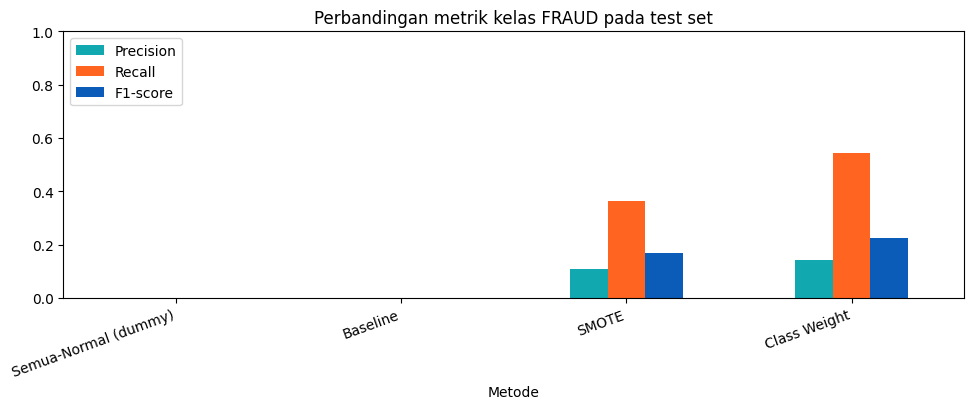

In [13]:
# Grafik perbandingan Recall dan F1
ax = tabel[["Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(10, 4.2), color=["#12a8b0", "#ff6420", "#0b5cb8"])
ax.set_title("Perbandingan metrik kelas FRAUD pada test set")
ax.set_ylim(0, 1)
ax.set_xticklabels(tabel.index, rotation=20, ha="right")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

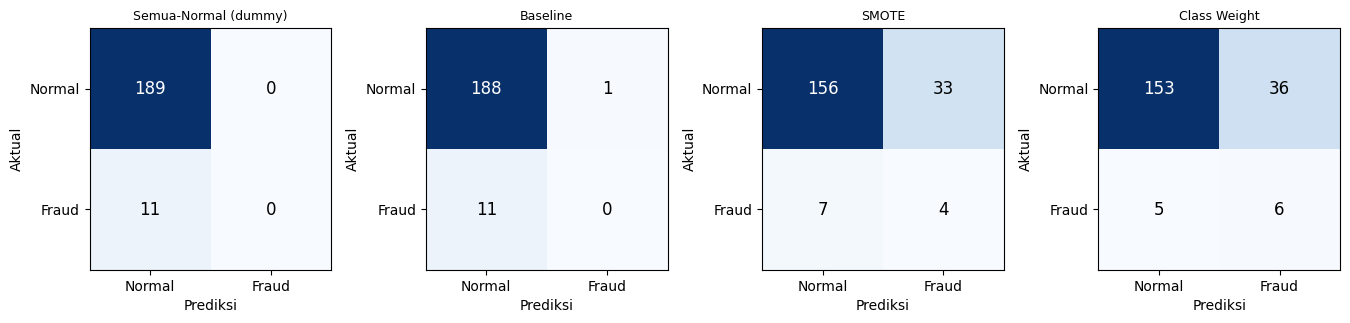

In [14]:
# Confusion matrix tiap metode
nama_list = list(cm_simpan.keys())
fig, axes = plt.subplots(1, len(nama_list), figsize=(3.4 * len(nama_list), 3.4))
for ax, nama in zip(axes, nama_list):
    cm = cm_simpan[nama]
    ax.imshow(cm, cmap="Blues")
    ax.set_title(nama, fontsize=9)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Normal", "Fraud"]); ax.set_yticklabels(["Normal", "Fraud"])
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
#11. Output 2: Keputusan dan alasan memilih teknik

In [16]:
kandidat = tabel.drop(index="Semua-Normal (dummy)")

terbaik_f1 = kandidat["F1-score"].idxmax()
tebaik_rc = kandidat["Recall"].idxmax()

print("=" * 60)
print("RINGKASAN KEPUTUSAN")
print("=" * 60)
print(f"Akurasi model 'semua normal'       : {tabel.loc['Semua-Normal (dummy)', 'Accuracy']:.1%} "
      f"(recall fraud = {tabel.loc['Semua-Normal (dummy)', 'Recall']:.0%})")
print(f"Metode dengan F1-score tertinggi   : {terbaik_f1} (F1 = {kandidat.loc[terbaik_f1, 'F1-score']:.3f})")
print(f"Metode dengan recall tertinggi     : {terbaik_rc} (Recall = {kandidat.loc[terbaik_rc, 'Recall']:.3f})")
print()
b = kandidat.loc["Baseline"]
for nama in ["SMOTE", "Class Weight"]:
    r = kandidat.loc[nama]
    print(f"{nama:<14}: recall {b['Recall']:.3f} -> {r['Recall']:.3f} | "
          f"precision {b['Precision']:.3f} -> {r['Precision']:.3f} | "
          f"F1 {b['F1-score']:.3f} -> {r['F1-score']:.3f} | "
          f"akurasi {b['Accuracy']:.3f} -> {r['Accuracy']:.3f}")

RINGKASAN KEPUTUSAN
Akurasi model 'semua normal'       : 94.5% (recall fraud = 0%)
Metode dengan F1-score tertinggi   : Class Weight (F1 = 0.226)
Metode dengan recall tertinggi     : Class Weight (Recall = 0.545)

SMOTE         : recall 0.000 -> 0.364 | precision 0.000 -> 0.108 | F1 0.000 -> 0.167 | akurasi 0.940 -> 0.800
Class Weight  : recall 0.000 -> 0.545 | precision 0.000 -> 0.143 | F1 0.000 -> 0.226 | akurasi 0.940 -> 0.795
